In [133]:
from pathlib import Path
import subprocess

import numpy as np
import pandas as pd
import plotly.express as px


# ============================================================
# Configuration
# ============================================================


METADATA_FILE = (
    "../../../data/manuscript/dysgalactiae_genomes_all.csv"
)

if False:
    BLAST_DB = Path(
    "../../BLASTdb/"
    "dysgalactiae.v.3/fasta"
    )

    BLAST_DB.mkdir(
        parents=True,
        exist_ok=True
    )

CDS_Z = 1.64

In [134]:
''' Metadata on all genomes were manually downloaded from https://www.bv-brc.org/view/Taxonomy/1334#view_tab=genomes'''

' Metadata on all genomes were manually downloaded from https://www.bv-brc.org/view/Taxonomy/1334#view_tab=genomes'

In [135]:
# ============================================================
# Load genome metadata
# ============================================================

df = pd.read_csv(
    METADATA_FILE,
    dtype={"Genome ID": str}
)

# Remove plasmids
df = df.loc[
    df["Genome Status"] != "Plasmid"
].copy()

# Derived QC metric
df["CDS-contig-ratio"] = (
    df["CDS"] / df["Contigs"]
)

print(f"Genomes after plasmid removal: {len(df):,}")

Genomes after plasmid removal: 321


In [136]:
def get_host_serotype(ref):
    ref = ref.copy()

    ref["Other Names"] = ref["Other Names"].astype(object)

    for col in [
        "Genome Name",
        "Host Common Name",
        "MLST",
        "Host Group",
    ]:
        ref[col] = ref[col].fillna("").astype(str)




    ref['Genome Name'] = (
        ref['Genome Name'].fillna('').astype(str)
    )


    for ix in ref.index:
        name=ref.loc[ix,'Genome Name']

        if 'subsp. dysgalactiae' in ref.loc[ix,'Genome Name']:
            ref.loc[ix,'Other Names']='SDSD'
        if 'SDSD' in ref.loc[ix,'Genome Name']:
            ref.loc[ix,'Other Names']='SDSD'
        if 'Cow' in ref.loc[ix,'Host Common Name']:
            ref.loc[ix,'Other Names']='SDSD'
        if 'equisimilis' in ref.loc[ix,'Genome Name']:
            ref.loc[ix,'Other Names']='SDSE'
        if 'SDSE' in name:
            ref.loc[ix,'Other Names']='SDSE'
        if 'equisimilis' in ref.loc[ix,'MLST']:
            ref.loc[ix,'Other Names']='SDSE'
        if 'Human' in ref.loc[ix,'Host Group']:
            ref.loc[ix,'Other Names']='SDSE'





    nonhuman_mammal=['Rhinoceros unicornis','Greater one-horned rhinoceros','Seriola dumerili','Puppy','Ictalurus punctatus','Chaetophractus villosus']
    food=['Food','food']
    human=['Human, Homo sapiens','Homo sapiens subsp sapiens']


    for ix in ref.index:
        source=ref.loc[ix,'Isolation Source']
        host=ref.loc[ix,'Host Name']
        if host in nonhuman_mammal:
            ref.loc[ix,'Host Group']='Nonhuman Mammal'
        if host in human:
            ref.loc[ix,'Host Group']='Human'
        if source in food:
            ref.loc[ix,'Host Group']='Food'

        elif source =='fish':
            ref.loc[ix,'Host Group']='Fish'
        elif source in ['human skin','Hospital Bedding']:
           ref.loc[ix,'Host Group']='Human'
    return ref


In [137]:
df=get_host_serotype(df)

In [138]:
# ============================================================
# CDS-based QC
# ============================================================

cds_mean = df["CDS"].mean()
cds_std = df["CDS"].std()

cds_lower = cds_mean - CDS_Z * cds_std
cds_upper = cds_mean + CDS_Z * cds_std

df["CDS_outlier"] = ~df["CDS"].between(
    cds_lower,
    cds_upper
)

print(f"CDS mean: {cds_mean:.1f}")
print(f"CDS SD:   {cds_std:.1f}")
print(
    f"Accepted CDS range: "
    f"{cds_lower:.1f}–{cds_upper:.1f}"
)

CDS mean: 2173.8
CDS SD:   569.1
Accepted CDS range: 1240.5–3107.2


In [139]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_genome_qc(
    df,
    x="CDS",
    y="Contigs",
    lower_bound=None,
    upper_bound=None,
    title="Genome QC",
    bins=20,
    save=False,
    filename="genome_qc.pdf",
):

    plot_df = df[[x, y]].dropna().copy()

    if lower_bound is not None and upper_bound is not None:
        plot_df["QC"] = np.where(
            plot_df[x].between(lower_bound, upper_bound),
            "Included",
            "Outlier"
        )
    else:
        plot_df["QC"] = "Included"

    included = plot_df[plot_df["QC"] == "Included"]
    outliers = plot_df[plot_df["QC"] == "Outlier"]

    # --------------------------------------------------------
    # Figure layout
    # --------------------------------------------------------

    plt.style.use("default")

    fig = plt.figure(
        figsize=(8, 6),
        facecolor="white"
    )

    gs = fig.add_gridspec(
        2,
        2,
        width_ratios=[4, 1],
        height_ratios=[1, 4],
        wspace=0.05,
        hspace=0.05
    )

    ax_main = fig.add_subplot(gs[1, 0])
    ax_top = fig.add_subplot(gs[0, 0], sharex=ax_main)
    ax_right = fig.add_subplot(gs[1, 1], sharey=ax_main)

    # --------------------------------------------------------
    # Scatter plot
    # --------------------------------------------------------

    ax_main.scatter(
        included[x],
        included[y],
        s=39,
        color="#008000",  # stronger natural green
        edgecolor="black",
        linewidth=0.2,
        alpha=0.8
    )

    if not outliers.empty:
        ax_main.scatter(
            outliers[x],
            outliers[y],
            s=40,
            color="#FF0000",
            edgecolor="black",
            linewidth=0.4,
            alpha=0.9
        )

    # --------------------------------------------------------
    # QC boundaries
    # --------------------------------------------------------

    line_kwargs = dict(
        color="gray",
        linewidth=1.3,
        linestyle=(0, (10, 6)),
        zorder=0
    )

    for bound in [lower_bound, upper_bound]:
        if bound is not None:
            ax_main.axvline(bound, **line_kwargs)
            ax_top.axvline(bound, **line_kwargs)

    # --------------------------------------------------------
    # Marginal histograms
    # --------------------------------------------------------

    ax_top.hist(
        included[x],
        bins=bins,
        color="#008000" , # stronger natural green
        edgecolor="black",
        linewidth=0.4,
        alpha=0.8
    )

    if not outliers.empty:
        ax_top.hist(
            outliers[x],
            bins=bins,
            color="#FF0000",
            edgecolor="black",
            linewidth=0.4,
            alpha=0.8
        )

    ax_right.hist(
        included[y],
        bins=bins,
        orientation="horizontal",
        color="#008000",  # stronger natural green,
        edgecolor="black",
        linewidth=0.4,
        alpha=0.8
    )

    if not outliers.empty:
        ax_right.hist(
            outliers[y],
            bins=bins,
            orientation="horizontal",
            color="#FF0000",
            edgecolor="black",
            linewidth=0.4,
            alpha=0.8
        )

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    ax_main.set_xlabel(x, fontsize=14)
    ax_main.set_ylabel(y, fontsize=14)

    fig.suptitle(
        title,
        fontsize=16,
        y=0.96
    )

    # --------------------------------------------------------
    # Fewer ticks on main axes
    # --------------------------------------------------------

    # Fixed CDS ticks
    ax_main.set_xticks([0, 2000, 4000, 6000])

    # Fewer ticks for Contigs
    ax_main.yaxis.set_major_locator(
        MaxNLocator(nbins=5)
    )

    ax_main.tick_params(
        axis="both",
        labelsize=11
    )

    # --------------------------------------------------------
    # Clean marginal axes
    # --------------------------------------------------------

    # No labels/ticks on top histogram
    ax_top.tick_params(
        axis="x",
        bottom=False,
        labelbottom=False
    )

    ax_top.tick_params(
        axis="y",
        left=False,
        labelleft=False
    )

    # No labels/ticks on right histogram
    ax_right.tick_params(
        axis="x",
        bottom=False,
        labelbottom=False
    )

    ax_right.tick_params(
        axis="y",
        left=False,
        labelleft=False
    )

    # --------------------------------------------------------
    # Styling
    # --------------------------------------------------------

    for ax in [ax_main, ax_top, ax_right]:
        ax.set_facecolor("white")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    # Remove inner marginal borders
    ax_top.spines["bottom"].set_visible(False)
    ax_top.spines["left"].set_visible(False)

    ax_right.spines["left"].set_visible(False)
    ax_right.spines["bottom"].set_visible(False)

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------
    if True:
        fig.savefig(
            "genome_qc.png",
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()

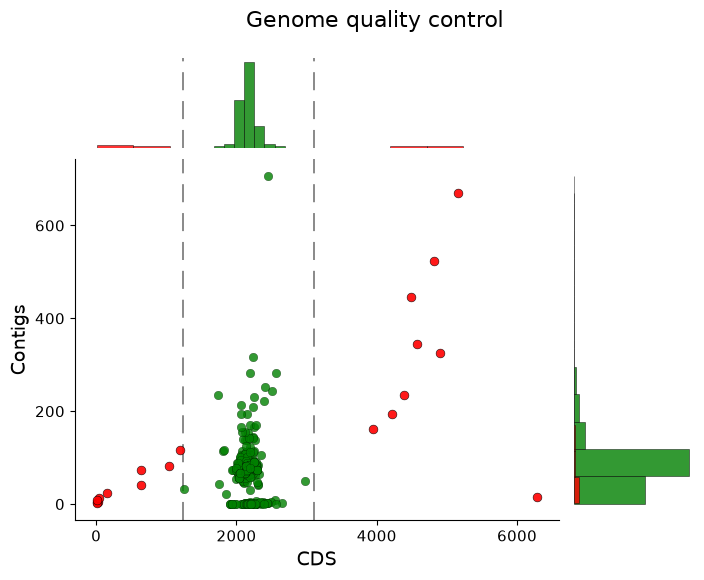

In [140]:
plot_genome_qc(
    df,
    x="CDS",
    y="Contigs",
    bins=12,
    save=True,
    lower_bound=cds_lower,
    upper_bound=cds_upper,
    title="Genome quality control"
)



In [141]:
# ============================================================
# Known duplicate genomes
# ============================================================

DUPLICATE_NAMES = [
    "Streptococcus dysgalactiae subsp. equisimilis strain UT-5345",
    "Streptococcus dysgalactiae subsp. equisimilis strain UT-5354",
    "Streptococcus dysgalactiae 1D-405",
    "Streptococcus dysgalactiae LSDV_89_mw_b2",
]

DUPLICATE_IDS = [
    "119602.324",
    "119602.325",
]

In [142]:
# ============================================================
# Genome QC masks
# ============================================================

host_missing = (
    df["Host Name"].isna()
    & df["Host Common Name"].isna()
    & df["Host Group"].isna()
)

host_not_annotated = (
    df["Host Name"]
    .fillna("")
    .str.strip()
    .str.lower()
    .pipe(lambda x: x.str.contains("not") | x.eq(""))
)
other_name_missing = (
    df["Other Names"].isna()
    | df["Other Names"].fillna("").str.strip().eq("")
)
qc_masks = {
    "Duplicated": (
        df["Genome ID"].isin(DUPLICATE_IDS)
        | df["Genome Name"].isin(DUPLICATE_NAMES)
    ),

    "Deprecated": (
        df["Genome Status"] == "Deprecated"
    ),

    "Lack of Host Annotation": (
        host_missing | host_not_annotated
    ),
    "Other Name Missing": (
        other_name_missing
    ),
    "Not Applicable": (
        df["Strain"]
        .fillna("")
        .str.lower()
        .eq("not applicable")
    ),

    "CDS Outlier": (
        df["CDS_outlier"]
    ),

    "Poor Quality": (
        df["Genome Quality"] == "Poor"
    ),
}

In [143]:
qc_summary = pd.Series({
    name: mask.sum()
    for name, mask in qc_masks.items()
}).sort_values(ascending=False)

print(qc_summary)

Lack of Host Annotation    63
Other Name Missing         44
Deprecated                 40
Poor Quality               20
CDS Outlier                19
Duplicated                  6
Not Applicable              5
dtype: int64


In [144]:
mask_df = pd.DataFrame(qc_masks)

mask_df.columns = [
    f"{col} ({mask_df[col].sum()})"
    for col in mask_df.columns
]

In [145]:
exclude_mask = np.logical_or.reduce(
    list(qc_masks.values())
)

df_filtered = df.loc[
    ~exclude_mask
].copy()

print(f"Genomes before QC: {len(df):,}")
print(f"Genomes after QC:  {len(df_filtered):,}")
print(f"Excluded:          {exclude_mask.sum():,}")

Genomes before QC: 321
Genomes after QC:  193
Excluded:          128


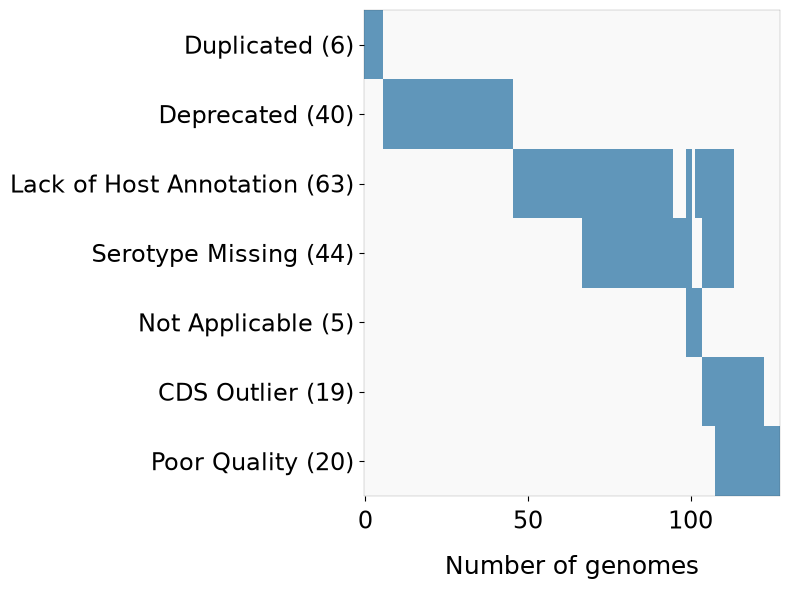

In [146]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, leaves_list
from matplotlib.colors import ListedColormap


# ============================================================
# Prepare data
# ============================================================

# Convert boolean values to integers
mask_df = mask_df.astype(int)

# Drop rows where all values are 0
mask_df = mask_df.loc[
    (mask_df != 0).any(axis=1)
].copy()


# ============================================================
# Hierarchical clustering
# ============================================================

linkage_matrix = linkage(
    mask_df,
    method="ward"
)

clustered_order = leaves_list(
    linkage_matrix
)

# Reorder genomes according to clustering
mask_df_clustered = mask_df.iloc[
    clustered_order
].copy()
mask_df_clustered = mask_df_clustered.rename(
    columns={
        "Other Name Missing (44)": "Serotype Missing (44)"
    }
)

# ============================================================
# Reorder selected genome groups
# ============================================================

duplicated = mask_df_clustered["Duplicated (6)"] == 1

deprecated = (
    (mask_df_clustered["Deprecated (40)"] == 1)
    & ~duplicated
)

poor_quality = (
    (mask_df_clustered["Poor Quality (20)"] == 1)
    & ~duplicated
    & ~deprecated
)

cds_outlier = (
    (mask_df_clustered["CDS Outlier (19)"] == 1)
    & ~duplicated
    & ~deprecated
    & ~poor_quality
)

not_applicable = (
    (mask_df_clustered["Not Applicable (5)"] == 1)
    & ~duplicated
    & ~deprecated
    & ~poor_quality
    & ~cds_outlier
)

other = (
    ~duplicated
    & ~deprecated
    & ~not_applicable
    & ~cds_outlier
    & ~poor_quality
)

mask_df_clustered = pd.concat([
    mask_df_clustered.loc[duplicated],
    mask_df_clustered.loc[deprecated],
    mask_df_clustered.loc[other],
    mask_df_clustered.loc[not_applicable],
    mask_df_clustered.loc[cds_outlier],
    mask_df_clustered.loc[poor_quality]
])

mask_df_clustered.reset_index(
    drop=True,
    inplace=True
)


# ============================================================
# Plot
# ============================================================

# Same colors as your Plotly figure
cmap = ListedColormap([
    "#F9F9F9",
    "#6096ba"
])

fig, ax = plt.subplots(
    figsize=(8, 6),
    facecolor="white"
)

ax.set_facecolor("white")

im = ax.imshow(
    mask_df_clustered.T,
    aspect="auto",
    interpolation="none",
    cmap=cmap,
    vmin=0,
    vmax=1
)


# ============================================================
# Labels
# ============================================================

ax.set_title(
    "",
    fontsize=18
)

ax.set_xlabel(
    "Number of genomes",
    fontsize=18,
    labelpad=15
)

ax.set_ylabel(
    "",
    fontsize=18
)

ax.set_yticks(
    np.arange(len(mask_df_clustered.columns))
)

ax.set_yticklabels(
    mask_df_clustered.columns,
    fontsize=17
)

ax.tick_params(
    axis="x",
    labelsize=17,
    pad=7
)


# ============================================================
# Appearance
# ============================================================

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(0.1)

fig.tight_layout()

plt.show()

In [123]:
fig.tight_layout()

fig.savefig(
    "heatmap_excluded_genomes.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [13]:
def download_protein_fasta(
    genome_ids,
    output_dir,
    overwrite=False,
):
    """
    Download protein FASTA files from BV-BRC using p3-genome-fasta.
    """

    output_dir = Path(output_dir)
    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    failed = []

    for genome_id in genome_ids:

        genome_id = str(genome_id)
        fasta_file = output_dir / f"{genome_id}.fasta"

        # Skip existing non-empty files
        if (
            fasta_file.exists()
            and fasta_file.stat().st_size > 0
            and not overwrite
        ):
            continue

        print(f"Downloading {genome_id}")

        try:
            with open(fasta_file, "w") as handle:

                subprocess.run(
                    [
                        "p3-genome-fasta",
                        "--protein",
                        genome_id,
                    ],
                    stdout=handle,
                    stderr=subprocess.PIPE,
                    text=True,
                    check=True,
                )

        except subprocess.CalledProcessError as e:

            print(
                f"Failed: {genome_id}\n"
                f"{e.stderr}"
            )

            failed.append(genome_id)

            # Remove failed/empty output
            if fasta_file.exists():
                fasta_file.unlink()

    return failed

In [ ]:
failed_ids = download_protein_fasta(
    df_filtered["Genome ID"],
    BLAST_DB,
)

print(f"Failed downloads: {len(failed_ids)}")
print(failed_ids)

In [ ]:
def find_missing_fasta(
    genome_ids,
    fasta_dir,
):

    fasta_dir = Path(fasta_dir)

    available = {
        f.stem
        for f in fasta_dir.glob("*.fasta")
        if f.stat().st_size > 0
    }

    expected = {
        str(x)
        for x in genome_ids
    }

    return sorted(expected - available)

In [ ]:
missing_ids = find_missing_fasta(
    df_filtered["Genome ID"],
    BLAST_DB,
)

print(
    f"Missing FASTA files: {len(missing_ids)}"
)

print(missing_ids)

In [ ]:
if missing_ids:

    failed_again = download_protein_fasta(
        missing_ids,
        BLAST_DB,
        overwrite=True,
    )

    print(
        f"Still missing after retry: "
        f"{len(failed_again)}"
    )

# Remove empty fasta files

In [ ]:
def remove_empty_fasta_files(directory):

    directory = Path(directory)

    empty_files = [
        f
        for f in directory.glob("*.fasta")
        if f.stat().st_size == 0
    ]

    for file in empty_files:
        print(f"Removing empty file: {file}")
        file.unlink()

    print(
        f"Removed {len(empty_files)} empty FASTA files"
    )

In [ ]:
remove_empty_fasta_files(BLAST_DB)